<a href="https://colab.research.google.com/github/Gugasc/Treinamento_Xception_Tomorrow/blob/main/Teste_Xception.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 9.6 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
import PIL.Image, PIL.ImageOps
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from keras.src.callbacks import EarlyStopping
import os
from shutil import copyfile

In [ ]:
import random
from glob import glob
from tqdm import tqdm
from collections import Counter

from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder

import plotly.express as px

from tensorflow.keras.applications import Xception

from tensorflow.keras import layers
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint

from keras_tuner.tuners import Hyperband
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.models import Model

from tensorflow.keras.applications.xception import preprocess_input

import shutil

In [ ]:
CLASSES = 15
TAMANHO_IMAGEM = (224, 224, 3)
DIRETORIO_PRAGAS = "/content/drive/MyDrive/dataset/farm_insects"
DIRETORIO_AGROTOXICOS = "/content/drive/MyDrive/dataset/agrofitprodutosformulados.csv"

In [ ]:
agrotoxicos_data = pd.read_csv(DIRETORIO_AGROTOXICOS, sep=";")
agrotoxicos_data.head()

,NR_REGISTRO,MARCA_COMERCIAL,FORMULACAO,INGREDIENTE_ATIVO,TITULAR_DE_REGISTRO,CLASSE,MODO_DE_ACAO,CULTURA,PRAGA_NOME_CIENTIFICO,PRAGA_NOME_COMUM,EMPRESA_PAIS_TIPO,CLASSE_TOXICOLOGICA,CLASSE_AMBIENTAL,ORGANICOS,SITUACAO
0,35523,KBR-829M1-02,Nematóides vivos,Heterorhabditis bacteriophora (Nematóides ento...,Koppert do Brasil Holding S.A. - Piracicaba/SP,Agente Biológico de Controle,NaN,Todas as culturas,Scaptocoris castanea,Percevejo-castanho,(Koppert do Brasil Holding S.A. - Piracicaba/...,Não Classificado - Produto Não Classificado,Produto Pouco Perigoso ao Meio Ambiente,NAO,True
1,35523,KBR-829M1-02,Nematóides vivos,Heterorhabditis bacteriophora (Nematóides ento...,Koppert do Brasil Holding S.A. - Piracicaba/SP,Agente Biológico de Controle,NaN,Todas as culturas,Sphenophorus levis,Bicudo da cana-de-açúcar; Gorgulho-da-cana,(Koppert do Brasil Holding S.A. - Piracicaba/...,Não Classificado - Produto Não Classificado,Produto Pouco Perigoso ao Meio Ambiente,NAO,True
2,35523,KBR-829M1-02,Nematóides vivos,Heterorhabditis bacteriophora (Nematóides ento...,Koppert do Brasil Holding S.A. - Piracicaba/SP,Agente Biológico de Controle,NaN,Todas as culturas,Spodoptera frugiperda,Lagarta-militar,(Koppert do Brasil Holding S.A. - Piracicaba/...,Não Classificado - Produto Não Classificado,Produto Pouco Perigoso ao Meio Ambiente,NAO,True
3,33723,KBR-S39M1-02,Nematóides vivos,Steinernema carpocapsae (Nematóides entomopato...,Koppert do Brasil Holding S.A. - Piracicaba/SP,Agente Biológico de Controle,NaN,Todas as culturas,Bradysia matogrossensis,fungus gnats,(Koppert do Brasil Holding S.A. - Piracicaba/...,Não Classificado - Produto Não Classificado,Produto Pouco Perigoso ao Meio Ambiente,NAO,True
4,33723,KBR-S39M1-02,Nematóides vivos,Steinernema carpocapsae (Nematóides entomopato...,Koppert do Brasil Holding S.A. - Piracicaba/SP,Agente Biológico de Controle,NaN,Todas as culturas,Sphenophorus levis,Bicudo da cana-de-açúcar; Gorgulho-da-cana,(Koppert do Brasil Holding S.A. - Piracicaba/...,Não Classificado - Produto Não Classificado,Produto Pouco Perigoso ao Meio Ambiente,NAO,True


In [ ]:
agrotoxicos_data.drop(columns=["NR_REGISTRO","MARCA_COMERCIAL","FORMULACAO","TITULAR_DE_REGISTRO","CLASSE", "MODO_DE_ACAO","EMPRESA_PAIS_TIPO","CLASSE_TOXICOLOGICA", "SITUACAO"], inplace=True)

In [ ]:
agrotoxicos_data.isnull().sum()

,0
INGREDIENTE_ATIVO,8
CULTURA,31
PRAGA_NOME_CIENTIFICO,829
PRAGA_NOME_COMUM,2264
CLASSE_AMBIENTAL,0
ORGANICOS,0


In [ ]:
agrotoxicos_data.dropna(inplace=True)

In [ ]:
NOMES_CLASSES = os.listdir(DIRETORIO_PRAGAS)
for index, item in enumerate(NOMES_CLASSES):
  print(f"{index + 1}.{item}:",len(os.listdir(DIRETORIO_PRAGAS + "/" + item)))

1.Brown Marmorated Stink Bugs: 114
2.Citrus Canker: 104
3.Fall Armyworms: 113
4.Armyworms: 96
5.Corn Earworms: 110
6.Aphids: 88
7.Africanized Honey Bees (Killer Bees): 97
8.Colorado Potato Beetles: 112
9.Corn Borers: 115
10.Cabbage Loopers: 104
11.Thrips: 109
12.Spider Mites: 119
13.Tomato Hornworms: 109
14.Fruit Flies: 101
15.Western Corn Rootworms: 100
16.teste: 15
17.treino: 15


In [ ]:
agrotoxicos_data.head()

,INGREDIENTE_ATIVO,CULTURA,PRAGA_NOME_CIENTIFICO,PRAGA_NOME_COMUM,CLASSE_AMBIENTAL,ORGANICOS
0,Heterorhabditis bacteriophora (Nematóides ento...,Todas as culturas,Scaptocoris castanea,Percevejo-castanho,Produto Pouco Perigoso ao Meio Ambiente,NAO
1,Heterorhabditis bacteriophora (Nematóides ento...,Todas as culturas,Sphenophorus levis,Bicudo da cana-de-açúcar; Gorgulho-da-cana,Produto Pouco Perigoso ao Meio Ambiente,NAO
2,Heterorhabditis bacteriophora (Nematóides ento...,Todas as culturas,Spodoptera frugiperda,Lagarta-militar,Produto Pouco Perigoso ao Meio Ambiente,NAO
3,Steinernema carpocapsae (Nematóides entomopato...,Todas as culturas,Bradysia matogrossensis,fungus gnats,Produto Pouco Perigoso ao Meio Ambiente,NAO
4,Steinernema carpocapsae (Nematóides entomopato...,Todas as culturas,Sphenophorus levis,Bicudo da cana-de-açúcar; Gorgulho-da-cana,Produto Pouco Perigoso ao Meio Ambiente,NAO


In [ ]:
cient = {}

cient['Brown Marmorated Stink Bugs'] = 'Halyomorpha halys'
cient['Citrus Canker'] = 'Xanthomonas citri subsp. citri'
cient['Fall Armyworms'] = 'Spodoptera frugiperda'
cient['Armyworms'] = 'Spodoptera'
cient['Corn Earworms'] = 'Helicoverpa zea'
cient['Aphids'] = 'Aphidoidea (Superfamily)'
cient['Africanized Honey Bees (Killer Bees)'] = 'Apis mellifera'
cient['Colorado Potato Beetles'] = 'Leptinotarsa decemlineata'
cient['Corn Borers'] = 'Ostrinia nubilalis'
cient['Cabbage Loopers'] = 'Trichoplusia ni'
cient['Thrips'] = 'Frankliniella occidentalis'
cient['Spider Mites'] = 'Tetranychidae'
cient['Tomato Hornworms'] = 'Manduca quinquemaculata'
cient['Fruit Flies'] = 'Ceratitis capitata'
cient['Western Corn Rootworms'] = 'Diabrotica virgifera virgifera'

In [ ]:
print(f"\nTotal de nomes comuns na lista: {len(NOMES_CLASSES)}")
print(f"Total de nomes mapeados no dicionário: {len(cient)}")


Total de nomes comuns na lista: 17
Total de nomes mapeados no dicionário: 15


In [ ]:
def separar_imagens_treino_teste(diretorio_imagem, diretorio_treino, diretorio_teste, random_state=None, shuffle=True, train_size=0.8):

    for classe in os.listdir(diretorio_imagem):
        caminho_completo_classe = os.path.join(diretorio_imagem, classe)

        # garante que a classe é um diretório antes de processá-lo
        if not os.path.isdir(caminho_completo_classe):
            continue

        os.makedirs(os.path.join(diretorio_treino, classe), exist_ok=True)
        os.makedirs(os.path.join(diretorio_teste, classe), exist_ok=True)

        imagens_da_classe = []
        # filtra apenas as imagens dentro da pasta da classe
        for item in os.listdir(caminho_completo_classe):
            caminho_item_completo = os.path.join(caminho_completo_classe, item)
            if os.path.isfile(caminho_item_completo):
                imagens_da_classe.append(item)

        quantidade_imagens = len(imagens_da_classe)

        # verifica se há imagens para dividir antes de chamar train_test_split
        if quantidade_imagens == 0:
            print(f"Classe: {classe} - Nenhuma imagem encontrada para processar.")
            continue

        imagens_treino, imagens_teste = train_test_split(imagens_da_classe, test_size=1-train_size, random_state=random_state, shuffle=shuffle)

        for imagem in imagens_treino:
            # garante que a imagem é um arquivo, antes de copiar
            shutil.copyfile(os.path.join(caminho_completo_classe, imagem), os.path.join(diretorio_treino, classe, imagem))
        for imagem in imagens_teste:
            # garante que a imagem é um arquivo, antes de copiar
            shutil.copyfile(os.path.join(caminho_completo_classe, imagem), os.path.join(diretorio_teste, classe, imagem))

        print(f"Classe: {classe}")
        print(f"Quantidade de imagens: {quantidade_imagens}")
        print(f"Quantidade de imagens de treino: {len(imagens_treino)}")
        print(f"Quantidade de imagens de teste: {len(imagens_teste)}")

separar_imagens_treino_teste(DIRETORIO_PRAGAS, DIRETORIO_PRAGAS + "/treino", DIRETORIO_PRAGAS + "/teste")

Classe: Brown Marmorated Stink Bugs
Quantidade de imagens: 114
Quantidade de imagens de treino: 91
Quantidade de imagens de teste: 23
Classe: Citrus Canker
Quantidade de imagens: 104
Quantidade de imagens de treino: 83
Quantidade de imagens de teste: 21
Classe: Fall Armyworms
Quantidade de imagens: 113
Quantidade de imagens de treino: 90
Quantidade de imagens de teste: 23
Classe: Armyworms
Quantidade de imagens: 96
Quantidade de imagens de treino: 76
Quantidade de imagens de teste: 20
Classe: Corn Earworms
Quantidade de imagens: 110
Quantidade de imagens de treino: 88
Quantidade de imagens de teste: 22
Classe: Aphids
Quantidade de imagens: 88
Quantidade de imagens de treino: 70
Quantidade de imagens de teste: 18
Classe: Africanized Honey Bees (Killer Bees)
Quantidade de imagens: 97
Quantidade de imagens de treino: 77
Quantidade de imagens de teste: 20
Classe: Colorado Potato Beetles
Quantidade de imagens: 112
Quantidade de imagens de treino: 89
Quantidade de imagens de teste: 23
Classe

In [ ]:
diretorio_treino  = DIRETORIO_PRAGAS + "/treino"
diretorio_teste = DIRETORIO_PRAGAS + "/teste"

classes_treino = os.listdir(diretorio_treino)
classes_teste = os.listdir(diretorio_teste)

y_train = []
y_test =[]
x_train = []
x_test = []

for classe in classes_treino:
  for imagem_nome in os.listdir(os.path.join(diretorio_treino, classe)):
    imagem_caminho = os.path.join(diretorio_treino, classe, imagem_nome)
    img = PIL.Image.open(imagem_caminho).convert('RGB')
    img = img.resize((TAMANHO_IMAGEM[0], TAMANHO_IMAGEM[1]))
    x_train.append(np.array(img))
    y_train.append(classe)


for classe in classes_teste:
  for imagem_nome in os.listdir(os.path.join(diretorio_teste, classe)):
    imagem_caminho = os.path.join(diretorio_teste, classe, imagem_nome)
    img = PIL.Image.open(imagem_caminho).convert('RGB')
    img = img.resize((TAMANHO_IMAGEM[0], TAMANHO_IMAGEM[1]))
    x_test.append(np.array(img))
    y_test.append(classe)

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1043: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


In [ ]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

y_train = np.array(to_categorical(y_train_encoded, num_classes=CLASSES))
y_test = np.array(to_categorical(y_test_encoded, num_classes=CLASSES))

x_train, x_test = np.array(x_train).astype('float32'), np.array(x_test).astype('float32')

In [ ]:
print(f"Shape x_train: {x_train.shape}")
print(f"Shape y_train: {y_train.shape}")
print(f"Shape x_test: {x_test.shape}")
print(f"Shape y_test: {y_test.shape}")

Shape x_train: (1268, 224, 224, 3)
Shape y_train: (1268, 15)
Shape x_test: (323, 224, 224, 3)
Shape y_test: (323, 15)


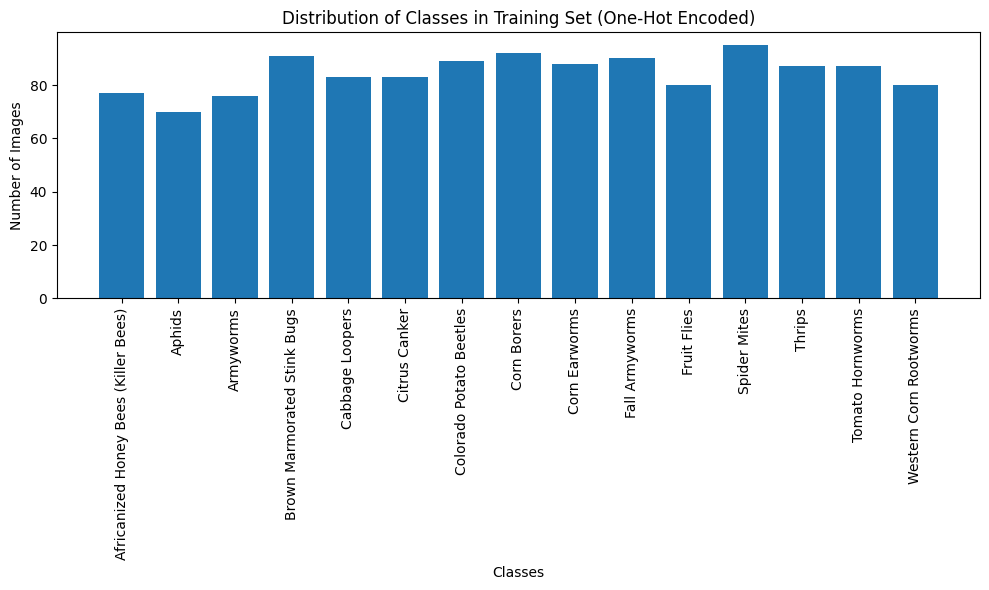

In [ ]:
class_names = label_encoder.inverse_transform(np.argmax(y_train, axis=1))

class_counts = pd.Series(class_names).value_counts()

class_counts = class_counts.sort_index()

plt.figure(figsize=(10, 6))
plt.bar(class_counts.index, class_counts.values)
plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Distribution of Classes in Training Set (One-Hot Encoded)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
# include_top=False remove as camadas de classificação finais, permitindo que você adicione as suas
xception_model = Xception(
    include_top=False,
    weights='imagenet',
    input_shape=TAMANHO_IMAGEM,
)

# congela as camadas do modelo base para evitar que os pesos pré-treinados sejam modificados
xception_model.trainable = False

input_tensor = Input(shape=TAMANHO_IMAGEM)

x = preprocess_input(input_tensor)

x = xception_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x) # dropout para regularização
output_tensor = Dense(CLASSES, activation='softmax')(x) # camada de saída com o número de classes e ativação softmax

model = Model(input_tensor, output_tensor)

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

r = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=20)

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_5 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_5 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 7, 7, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 15)             │        30,735 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,892,215 (79.70 MB)

 Trainable params: 30,735 (120.06 KB)

 Non-trainable params: 20,861,480 (79.58 MB)

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 21s 370ms/step - accuracy: 0.2325 - loss: 2.4295 - val_accuracy: 0.5294 - val_loss: 1.5415
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 207ms/step - accuracy: 0.6229 - loss: 1.3145 - val_accuracy: 0.6471 - val_loss: 1.2624
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 206ms/step - accuracy: 0.6987 - loss: 1.0063 - val_accuracy: 0.6533 - val_loss: 1.1409
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 172ms/step - accuracy: 0.7493 - loss: 0.8442 - val_accuracy: 0.6780 - val_loss: 1.0788
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 202ms/step - accuracy: 0.7949 - loss: 0.7382 - val_accuracy: 0.6842 - val_loss: 1.0421
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 10s 199ms/step - accuracy: 0.8376 - loss: 0.6499 - val_accuracy: 0.6997 - val_loss: 1.0081
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 10s 196ms/step - accuracy: 0.8501 - loss: 0.5716 - val_accuracy: 0.7090 - val_loss: 0.9879
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 10s 197ms/step - accuracy: 0.8438 - loss: 0.5642 - val_accurac

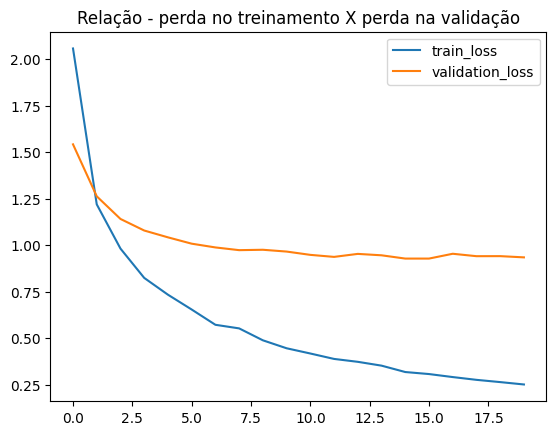

In [ ]:
plt.title("Relação - perda no treinamento X perda na validação")
plt.plot(r.history['loss'], label='train_loss')
plt.plot(r.history['val_loss'], label='validation_loss')
plt.legend()
plt.show()

In [ ]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=1)
print(f"Acurácia no teste: {format((accuracy) * 100, '.2f')}%")

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 121ms/step - accuracy: 0.7044 - loss: 0.9579
Acurácia no teste: 72.45%


In [ ]:
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

Found GPU at: /device:GPU:0


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


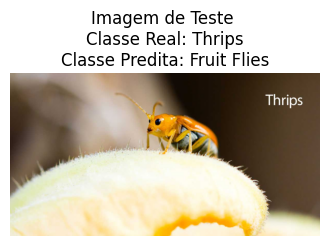

Imagem de teste escolhida para predição:
Classe Real (do dataset): Thrips
Classe Predita pelo modelo: Fruit Flies
Confiança da predição: 14.000000000000002%
Nome científico correspondente: Ceratitis capitata
Ingredientes Ativos Recomendados:
['clorpirifós (organofosforado) (480 g/L)', 'bifentrina (piretróide) (400 g/L)', 'malationa (organofosforado) (1000 g/L)', 'trimedlure (ésteres saturados) (558.8 g/kg)', 'Diachasmimorpha longicaudata (Biológico) (1500 parasitoides/sachê)', 'cipermetrina (piretróide) (250 g/L)', 'deltametrina (piretróide) (25 g/L)', 'fenpropatrina (piretróide) (300 g/L)', 'Espinetoram (espinosinas) (250 g/kg)', 'dimetoato (organofosforado) (500 g/L)', 'dimetoato (organofosforado) (400 g/L)', 'etofenproxi (éter difenílico) (500 g/L)', 'acetamiprido (neonicotinóide) (167 g/L) + etofenproxi (éter difenílico) (300 g/L)', 'alfa-cipermetrina (piretróide) (6 g/L)', 'fosmete (organofosforado) (500 g/kg)', 'Pupa estéril de macho de Ceratitis capitata linhagem tsl  (Biológico

In [ ]:
from sklearn.metrics import confusion_matrix

random_index = random.randint(0, len(x_test) - 1)
test_image_array = x_test[random_index]
true_label_encoded = np.argmax(y_test[random_index])
true_label = label_encoder.inverse_transform([true_label_encoded])[0]
if np.max(test_image_array) <= 1.0:
    test_image_for_processing = test_image_array * 255.0
else:
    test_image_for_processing = test_image_array.copy()

test_image_processed = np.expand_dims(test_image_for_processing, axis=0)
test_image_processed = tf.keras.applications.resnet_v2.preprocess_input(test_image_processed)

predictions = model.predict(test_image_processed)
predicted_class_index = np.argmax(predictions[0])
predicted_class_name = label_encoder.inverse_transform([predicted_class_index])[0]
confidence = np.max(predictions[0])

true_class_test_dir = os.path.join(diretorio_teste, true_label)
if os.path.isdir(true_class_test_dir):
    images_in_true_class = [f for f in os.listdir(true_class_test_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    if images_in_true_class:
        image_to_display_name = random.choice(images_in_true_class)
        image_to_display_path = os.path.join(true_class_test_dir, image_to_display_name)
        try:
            img_pil = Image.open(image_to_display_path)

            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Imagem de Teste \nClasse Real: {true_label}\nClasse Predita: {predicted_class_name}")
            plt.axis('off')
            plt.show()

        except Exception as e:
            print(f"Erro ao carregar ou exibir a imagem de demonstração: {e}")
    else:
        print(f"Nenhuma imagem encontrada no diretório de teste para a classe: {true_label}")
else:
    print(f"Diretório de teste para a classe '{true_label}' não encontrado: {true_class_test_dir}")


print(f"Imagem de teste escolhida para predição:")
print(f"Classe Real (do dataset): {true_label}")
print(f"Classe Predita pelo modelo: {predicted_class_name}")
confidence = float(format(confidence,'.2f'))
print(f"Confiança da predição: {confidence * 100}%")

nome_cientifico = ""
for key in cient:
  if predicted_class_name == key:
    nome_cientifico = cient[key]
    break

print(f"Nome científico correspondente: {nome_cientifico}")

agrotoxicos_data.head()

print("Ingredientes Ativos Recomendados:")
ingredientes_ativos_lista = agrotoxicos_data[agrotoxicos_data['PRAGA_NOME_CIENTIFICO'] == nome_cientifico]['INGREDIENTE_ATIVO'].unique().tolist()
print(ingredientes_ativos_lista)

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 131ms/step


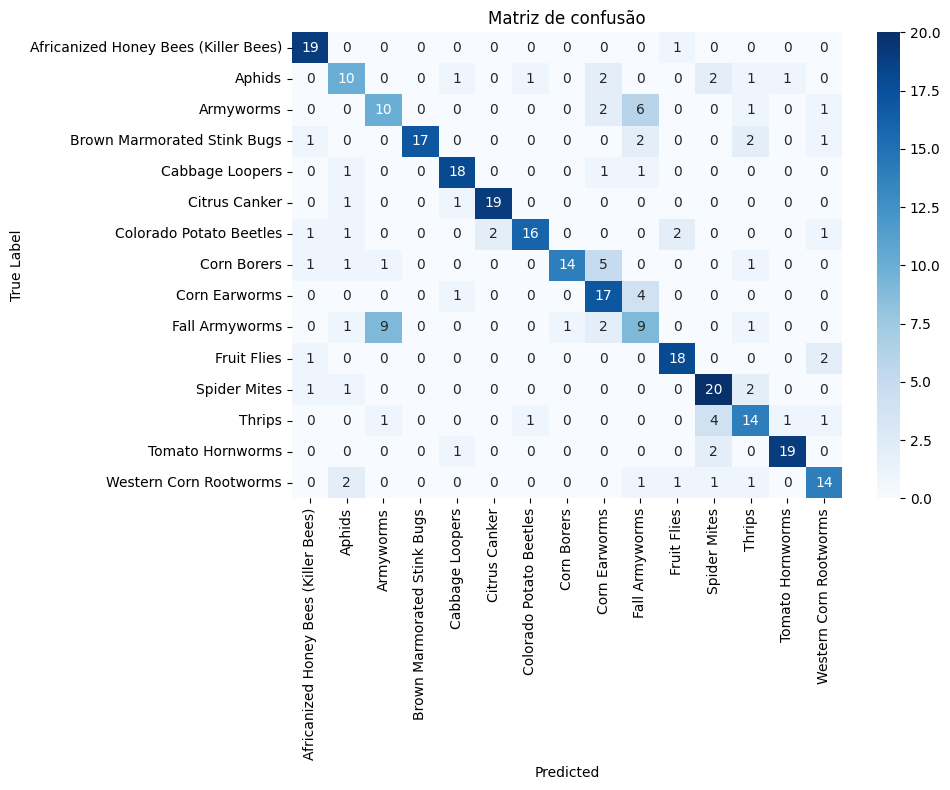

In [ ]:
import seaborn as sns
y_true = np.argmax(y_test,axis=1)
y_pred = np.argmax(model.predict(x_test),axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('True Label')
plt.title('Matriz de confusão')
plt.tight_layout()
plt.show()